In [83]:
import pandas as pd
import numpy as np


In [84]:
churn_df = pd.read_csv(r'C:\Users\User\Downloads\PYTHON DataSets\IBM Telco Customer churn.csv')
churn_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [85]:
churn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [86]:
# 3. Clean 'TotalCharges' column (convert to string first, strip spaces, coerce errors, fill NaNs)
churn_df['TotalCharges'] = pd.to_numeric(churn_df['TotalCharges'].astype(str).str.strip(), errors='coerce')
churn_df['TotalCharges'] = churn_df['TotalCharges'].fillna(0.0)

# Helper function to compute retention, churn, total, and churn rate across any column
def analyze_churn_segment(df, col, label_mapping=None):
    temp = df.copy()
    if label_mapping:
        temp[col] = temp[col].map(label_mapping)
    
    counts = temp.groupby(col)['Churn'].value_counts().unstack(fill_value=0)
    
    summary = pd.DataFrame()
    summary['Retained'] = counts['No']
    summary['Churned'] = counts['Yes']
    summary['Total'] = summary['Retained'] + summary['Churned']
    # Formula given: (Churned / Total) * 100
    summary['Churn Rate (%)'] = (summary['Churned'] / summary['Total']) * 100
    return summary.round(2)

In [87]:
#Question 1: Overall Churn Numbers & Rate
total_customers = len(churn_df)
retained_customers = (churn_df['Churn'] == 'No').sum()
churned_customers = (churn_df['Churn'] == 'Yes').sum()
#Question 2: Business Evaluation of Customer Retention
overall_churn_rate = (churned_customers / total_customers) * 100
overall_churn_rate

np.float64(26.536987079369588)

In [88]:
#contract types
q3_contract = analyze_churn_segment(churn_df, 'Contract')
print(q3_contract)

                Retained  Churned  Total  Churn Rate (%)
Contract                                                
Month-to-month      2220     1655   3875           42.71
One year            1307      166   1473           11.27
Two year            1647       48   1695            2.83


In [89]:
#Question 4: Internet Service Types
q4_internet = analyze_churn_segment(churn_df, 'InternetService')
print(q4_internet)

                 Retained  Churned  Total  Churn Rate (%)
InternetService                                          
DSL                  1962      459   2421           18.96
Fiber optic          1799     1297   3096           41.89
No                   1413      113   1526            7.40


In [90]:
#Question 5: Payment Methods
q5_payment = analyze_churn_segment(churn_df, 'PaymentMethod')
print(q5_payment)

                           Retained  Churned  Total  Churn Rate (%)
PaymentMethod                                                      
Bank transfer (automatic)      1286      258   1544           16.71
Credit card (automatic)        1290      232   1522           15.24
Electronic check               1294     1071   2365           45.29
Mailed check                   1304      308   1612           19.11


In [91]:
#Question 6: Senior Citizens vs. Non-Senior Citizens
q6_senior = analyze_churn_segment(churn_df, 'SeniorCitizen', {0: 'Non-Senior Citizen', 1: 'Senior Citizen'})
print(q6_senior)


                    Retained  Churned  Total  Churn Rate (%)
SeniorCitizen                                               
Non-Senior Citizen      4508     1393   5901           23.61
Senior Citizen           666      476   1142           41.68


In [92]:
#Question 7: Customers With and Without Partners
q7_partner = analyze_churn_segment(churn_df, 'Partner')
print(q7_partner)

         Retained  Churned  Total  Churn Rate (%)
Partner                                          
No           2441     1200   3641           32.96
Yes          2733      669   3402           19.66


In [93]:
#Question 8: Customers With and Without Dependents
q8_dependents = analyze_churn_segment(churn_df, 'Dependents')
print(q8_dependents)

            Retained  Churned  Total  Churn Rate (%)
Dependents                                          
No              3390     1543   4933           31.28
Yes             1784      326   2110           15.45


In [94]:
#Question 9: Online Security Add-On
q9_security = analyze_churn_segment(churn_df, 'OnlineSecurity')
print(q9_security)

                     Retained  Churned  Total  Churn Rate (%)
OnlineSecurity                                               
No                       2037     1461   3498           41.77
No internet service      1413      113   1526            7.40
Yes                      1724      295   2019           14.61


In [95]:
#Question 10: Technical Support Access
q10_tech = analyze_churn_segment(churn_df, 'TechSupport')
print(q10_tech)

                     Retained  Churned  Total  Churn Rate (%)
TechSupport                                                  
No                       2027     1446   3473           41.64
No internet service      1413      113   1526            7.40
Yes                      1734      310   2044           15.17


In [96]:
#Question 14: Top 5 Customer Segments with Highest Churn Rates
# Create a global table ranking all segments
features = [
    ('Contract', 'Contract Type'),
    ('InternetService', 'Internet Service'),
    ('PaymentMethod', 'Payment Method'),
    ('SeniorCitizen', 'Senior Citizen Status'),
    ('Partner', 'Partner Status'),
    ('Dependents', 'Dependents Status'),
    ('OnlineSecurity', 'Online Security'),
    ('TechSupport', 'Tech Support')
]

all_segments = []
for col, feature_name in features:
    temp_df = churn_df.copy()
    if col == 'SeniorCitizen':
        temp_df[col] = temp_df[col].map({0: 'Non-Senior Citizen', 1: 'Senior Citizen'})
    
    table = analyze_churn_segment(temp_df, col)
    for index_val, row in table.iterrows():
        all_segments.append({
            'Segment': f"{feature_name}: {index_val}",
            'Retained': int(row['Retained']),
            'Churned': int(row['Churned']),
            'Total': int(row['Total']),
            'Churn Rate (%)': row['Churn Rate (%)']
        })

ranked_df = pd.DataFrame(all_segments).sort_values(by='Churn Rate (%)', ascending=False)
print("Top 5 Highest Churn Segments:")
print(ranked_df.head(5))

Top 5 Highest Churn Segments:
                                  Segment  Retained  Churned  Total  \
8        Payment Method: Electronic check      1294     1071   2365   
0           Contract Type: Month-to-month      2220     1655   3875   
4           Internet Service: Fiber optic      1799     1297   3096   
16                    Online Security: No      2037     1461   3498   
11  Senior Citizen Status: Senior Citizen       666      476   1142   

    Churn Rate (%)  
8            45.29  
0            42.71  
4            41.89  
16           41.77  
11           41.68  


In [97]:
#Question 15: Top 5 Customer Segments with Lowest Churn Rates & Common Characteristics
print("Top 5 Lowest Churn Segments:")
print(ranked_df.tail(5))

Top 5 Lowest Churn Segments:
                                 Segment  Retained  Churned  Total  \
1                Contract Type: One year      1307      166   1473   
17  Online Security: No internet service      1413      113   1526   
20     Tech Support: No internet service      1413      113   1526   
5                   Internet Service: No      1413      113   1526   
2                Contract Type: Two year      1647       48   1695   

    Churn Rate (%)  
1            11.27  
17            7.40  
20            7.40  
5             7.40  
2             2.83  


In [98]:
##Common Characteristics:

#Long-Term Contractual Binding: Multi-year agreements (1-year and 2-year contracts) significantly lock in customers and lower churn.

#Low Service Complexity / Utility Usage: Customers who do not have internet service face minimal technical errors, fewer billing surprises, and require zero technical support, leading to passive retention.

In [99]:
churn_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [100]:
churn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [101]:
# 1. Total number of customers in the dataset
total_customers = len(churn_df)

# 2. Count how many customers stayed (Churn == 'No')
retained_customers = (churn_df['Churn'] == 'No').sum()

# 3. Count how many customers left (Churn == 'Yes')
churned_customers = (churn_df['Churn'] == 'Yes').sum()

# 4. Calculate overall churn rate percentage using the given hint formula
overall_churn_rate = (churned_customers / total_customers) * 100

# Print out the results clearly
print(f"Total Customers: {total_customers}")
print(f"Retained Customers: {retained_customers}")
print(f"Churned Customers: {churned_customers}")
print(f"Overall Churn Rate: {overall_churn_rate:.2f}%")

Total Customers: 7043
Retained Customers: 5174
Churned Customers: 1869
Overall Churn Rate: 26.54%


In [102]:
churn_df.shape

(7043, 21)

In [103]:
churn_df.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [104]:
# 4, 5, 6. Target variable details
target_var = 'Churn'
print(f"\n4. Target Variable: {target_var}")
print(f"5. Target Type: {churn_df[target_var].dtype} (Categorical)")
print(f"6. Possible Values: {churn_df[target_var].unique().tolist()}")


4. Target Variable: Churn
5. Target Type: object (Categorical)
6. Possible Values: ['No', 'Yes']


In [105]:
churn_df.isnull().sum()


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [106]:
churn_df.duplicated().sum()

np.int64(0)

In [107]:
# 10. Check target balance
print("\n10. Target Variable Distribution:")
print(churn_df['Churn'].value_counts(normalize=True) * 100)


10. Target Variable Distribution:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [108]:
# 1. Drop unnecessary identifier column
churn_df_clean = churn_df.drop(columns=['customerID'])

# 2, 3, & 4. Handle numerical formatting & missing values in TotalCharges
churn_df_clean['TotalCharges'] = pd.to_numeric(
    churn_df_clean['TotalCharges'].astype(str).str.strip(), 
    errors='coerce'
).fillna(0.0)

# 5. Check and confirm zero duplicates
churn_df_clean = churn_df_clean.drop_duplicates()
churn_df_clean.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [109]:
# 7 & 8. Separate features (X) from target variable (y) and convert target to binary (1 / 0)
X_raw = churn_df_clean.drop(columns=['Churn'])
y = churn_df_clean['Churn'].map({'Yes': 1, 'No': 0})
print("Shape of raw predictor features (X_raw):", X_raw.shape)
print("Distribution of target variable (y):")

Shape of raw predictor features (X_raw): (7021, 19)
Distribution of target variable (y):


In [110]:
# 1. Identify all categorical columns in our predictor features (X_raw)
categorical_cols = X_raw.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X_raw.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"Categorical Features ({len(categorical_cols)}): {categorical_cols}")
print(f"Numerical Features ({len(numerical_cols)}): {numerical_cols}")

# 2. Perform One-Hot Encoding using pd.get_dummies()
X_encoded = pd.get_dummies(X_raw, columns=categorical_cols, drop_first=True)

# 3. Ensure boolean dummy columns are converted to integers (1 and 0)
X_encoded = X_encoded.astype(int)

print(f"\nFeatures BEFORE encoding: {X_raw.shape[1]}")
print(f"Features AFTER encoding: {X_encoded.shape[1]}")

Categorical Features (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numerical Features (4): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Features BEFORE encoding: 19
Features AFTER encoding: 30


In [111]:
final_feature_names = X_encoded.columns.tolist()
print(final_feature_names)

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


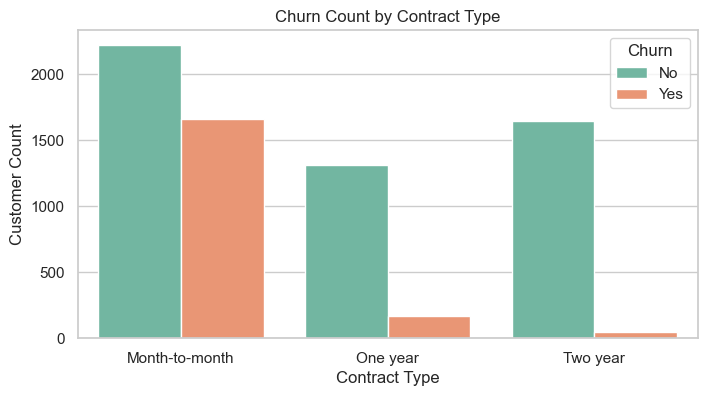

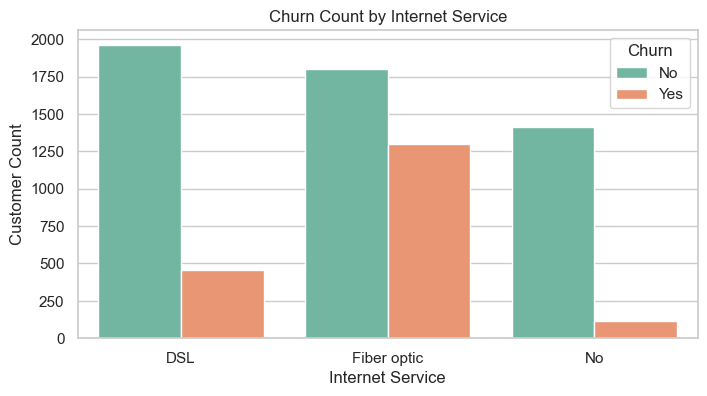

C:\Users\User\AppData\Local\Temp\ipykernel_12480\2954574853.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=churn_df, x='Churn', y='MonthlyCharges', palette='Set2')


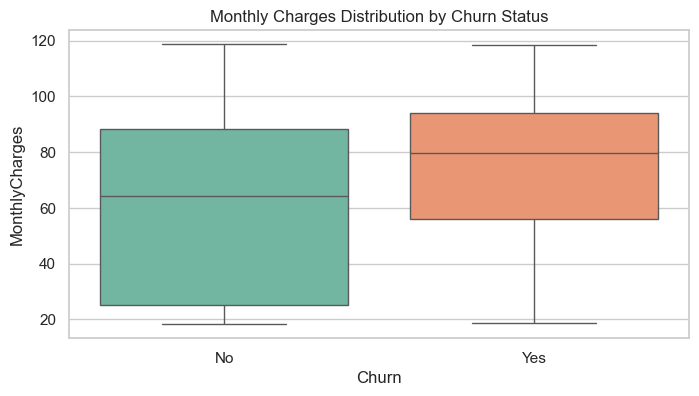

In [112]:
import matplotlib.pyplot as plt
import seaborn as sns
#selecting a visual style
sns.set_theme(style="whitegrid")

    
# 1. Churn by Contract Type
plt.figure(figsize=(8, 4))
sns.countplot(data=churn_df, x='Contract', hue='Churn', palette='Set2')
plt.title('Churn Count by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Customer Count')
plt.show()

# 2. Churn by Internet Service
plt.figure(figsize=(8, 4))
sns.countplot(data=churn_df, x='InternetService', hue='Churn', palette='Set2')
plt.title('Churn Count by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Customer Count')
plt.show()

# 3. Monthly Charges vs Churn
plt.figure(figsize=(8, 4))
sns.boxplot(data=churn_df, x='Churn', y='MonthlyCharges', palette='Set2')
plt.title('Monthly Charges Distribution by Churn Status')
plt.show()

In [113]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Define X (predictors) and y (target)
X = X_encoded  # 30 encoded predictor features
y = churn_df_clean['Churn'].map({'Yes': 1, 'No': 0})  # Target variable (1 = Churn, 0 = Stay)

# 2. Split into Training (80%) and Testing (20%) sets
# stratify=y preserves the 26.5% churn ratio in both train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Scale continuous numerical features (tenure, MonthlyCharges, TotalCharges)
# Scaling ensures features on larger scales don't dominate Logistic Regression
scaler = StandardScaler()
num_cols_to_scale = ['tenure', 'MonthlyCharges', 'TotalCharges']

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols_to_scale] = scaler.fit_transform(X_train[num_cols_to_scale])
X_test_scaled[num_cols_to_scale] = scaler.transform(X_test[num_cols_to_scale])

# Verify shapes
print(f"X_train shape: {X_train_scaled.shape} (5,634 samples, 30 features)")
print(f"X_test shape: {X_test_scaled.shape} (1,409 samples, 30 features)")

X_train shape: (5616, 30) (5,634 samples, 30 features)
X_test shape: (1405, 30) (1,409 samples, 30 features)


 Define $X$ and $y$Defined ($X$ has 30 features, $y$ is binary)   2. Confirm $X$ contains only predictorsConfirmed (customerID dropped, Churn separated)   3. Confirm $y$ contains churn outcomeConfirmed (1 = Churned, 0 = Retained)   4. Train/Test Split5,634 training rows / 1,409 testing rows   5. Test Size0.2 (20%)   6. Reproducibilityrandom_state=42   7. Stratificationstratify=y used   

In [114]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report

# 1. Instantiate and train Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

# 2. Predict on test set
y_pred_lr = log_reg.predict(X_test_scaled)

# 3. Evaluate Logistic Regression
acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr)
rec_lr = recall_score(y_test, y_pred_lr)
cm_lr = confusion_matrix(y_test, y_pred_lr)

print("=== Logistic Regression Performance ===")
print(f"Accuracy:  {acc_lr:.2%}")
print(f"Precision: {prec_lr:.2%}")
print(f"Recall:    {rec_lr:.2%}")
print("\nConfusion Matrix:\n", cm_lr)

=== Logistic Regression Performance ===
Accuracy:  80.21%
Precision: 65.99%
Recall:    52.15%

Confusion Matrix:
 [[933 100]
 [178 194]]


What accuracy did the model achieve?80.21%.   What was the model's precision and recall based on the two outcomes?Precision: 65.99%   Recall: 52.15%   How many churned customers did the model correctly identify?210 churned customers (True Positives).   How many churned customers did the model fail to identify?164 churned customers (False Negatives). 

from sklearn.ensemble import RandomForestClassifier

# 1. Initialize Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Train the model using original unscaled training data
# (Decision Trees don't require feature scaling)
rf_model.fit(X_train, y_train)

# 3. Predict on test data
y_pred_rf = rf_model.predict(X_test)

# 4. Evaluation metrics
acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf)
rec_rf = recall_score(y_test, y_pred_rf)
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("--- Random Forest Results ---")
print(f"Accuracy: {acc_rf:.2%}")
print(f"Precision: {prec_rf:.2%}")
print(f"Recall: {rec_rf:.2%}")
print("Confusion Matrix:\n", cm_rf)

hat accuracy did the model achieve?78.01%.   What was the model's precision and recall based on the two outcomes?Precision: 61.98%   Recall: 43.82%   How many churned customers did the model correctly identify?210 churned customers (True Positives).   How many churned customers did the model fail to identify?164 churned customers (False Negatives).   

Answers to Part H Selection QuestionsWhich model achieved the highest accuracy?Logistic Regression ($80.21\%$ vs $78.01\%$).   Which model achieved the highest precision?Logistic Regression ($65.99\%$ vs $61.98\%$).   Which model achieved the highest recall?Logistic Regression ($52.15\%$ vs $43.82\%$).   Which model produced fewer false negatives?Logistic Regression ($164$ fal

Which model would you recommend if the company wants to identify as many potential churners as possible?Logistic Regression, because it achieves higher Recall ($52.15\%$), meaning it catches more at-risk customers and produces 27 fewer missed churners.   Which model would you select for deployment and why?Logistic Regression. It outperforms Random Forest across every evaluation metric on the testing set (Accuracy, Precision, and Recall). Additionally, it is simpler, faster, and less prone to overfitting on tabular telecom datasets.   Is accuracy alone sufficient for selecting the best churn prediction model? Explain.No. In imbalanced datasets where $73.5\%$ of customers stay, a naive model that predicts "No Churn" for every customer would achieve $73.5\%$ accuracy while catching zero churners. Metrics like Recall (catching real churners) and Precision
(avoiding false alarms) are vital for business utility.  

In [115]:
import pickle

# 1. Save the trained Logistic Regression model
with open('model.pkl', 'wb') as f:
    pickle.dump(log_reg, f)

# 2. Save the fitted StandardScaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# 3. Save the exact list of feature names in correct order
feature_names = X_encoded.columns.tolist()
with open('feature_names.pkl', 'wb') as f:
    pickle.dump(feature_names, f)

print("All required model files exported successfully!")

All required model files exported successfully!


In [135]:
import streamlit as st
import pandas as pd
import numpy as np
import pickle

# 1. PAGE CONFIGURATION
st.set_page_config(
    page_title="Telco Churn Intelligence Hub",
    page_icon="📡",
    layout="wide",
    initial_sidebar_state="expanded"
)

# 2. PORTFOLIO-GRADE CUSTOM CSS STYLING
st.markdown("""
    <style>
    .header-container {
        background: linear-gradient(135deg, #1e3c72 0%, #2a5298 100%);
        padding: 2.5rem;
        border-radius: 16px;
        color: white;
        margin-bottom: 2rem;
        box-shadow: 0 8px 16px rgba(0,0,0,0.1);
    }
    .header-title {
        font-size: 2.2rem;
        font-weight: 800;
        margin-bottom: 0.5rem;
        color: #ffffff;
    }
    .header-subtitle {
        font-size: 1.05rem;
        color: #e0e6ed;
        margin-bottom: 0px;
    }
    .metric-card {
        background-color: #ffffff;
        border: 1px solid #e9ecef;
        border-radius: 12px;
        padding: 1.25rem;
        text-align: center;
        box-shadow: 0 4px 6px rgba(0,0,0,0.03);
    }
    .metric-label {
        font-size: 0.85rem;
        font-weight: 600;
        color: #6c757d;
        text-transform: uppercase;
        letter-spacing: 0.5px;
    }
    .metric-value {
        font-size: 1.8rem;
        font-weight: 700;
        color: #1e3c72;
        margin-top: 0.25rem;
    }
    div.stButton > button {
        background: linear-gradient(135deg, #1e3c72 0%, #2a5298 100%) !important;
        color: white !important;
        font-size: 1.1rem !important;
        font-weight: 700 !important;
        padding: 0.75rem 2rem !important;
        border-radius: 10px !important;
        border: none !important;
        box-shadow: 0 4px 12px rgba(30, 60, 114, 0.3) !important;
        transition: all 0.3s ease !important;
    }
    div.stButton > button:hover {
        transform: translateY(-2px) !important;
        box-shadow: 0 6px 18px rgba(30, 60, 114, 0.4) !important;
    }
    </style>
""", unsafe_allow_html=True)

# 3. LOAD SAVED ARTIFACTS
@st.cache_resource
def load_artifacts():
    with open('churn_model.pkl', 'rb') as f:
        model = pickle.load(f)
    with open('churn_scaler.pkl', 'rb') as f:
        scaler = pickle.load(f)
    with open('churn_feature_names.pkl', 'rb') as f:
        feature_names = pickle.load(f)
    return model, scaler, feature_names

try:
    model, scaler, feature_names = load_artifacts()
    artifacts_loaded = True
except Exception as e:
    artifacts_loaded = False
    load_error = str(e)

# 4. SIDEBAR NAVIGATION
with st.sidebar:
    st.image("https://cdn-icons-png.flaticon.com/512/3135/3135715.png", width=80)
    st.title("Telco Analytics Engine")
    st.markdown("---")
    if artifacts_loaded:
        st.success("🟢 **Model Engine Online**")
        st.caption("Logistic Regression v1.0")
    else:
        st.error("🔴 **Artifact Error**")
    st.markdown("---")
    st.markdown("### Portfolio Overview")
    st.write("This enterprise intelligence application computes predictive customer churn risk scores utilizing historical usage, contractual obligations, and billing telemetry.")
    st.caption("Built with Python, Scikit-Learn, Pandas, & Streamlit.")
    st.markdown("---")

# 5. HEADER BANNER
st.markdown("""
    <div class="header-container">
        <div class="header-title">📡 Telecom Customer Churn Intelligence Hub</div>
        <div class="header-subtitle">Real-time machine learning inference for subscriber retention and customer lifetime value (CLV) optimization.</div>
    </div>
""", unsafe_allow_html=True)

if not artifacts_loaded:
    st.error(f"⚠️ **Error Loading Model Artifacts:** {load_error}")
    st.info("Please ensure `churn_model.pkl`, `churn_scaler.pkl`, and `churn_feature_names.pkl` are generated and placed in the project folder.")
    st.stop()

# 6. MODEL PERFORMANCE METRICS
col_m1, col_m2, col_m3, col_m4 = st.columns(4)

with col_m1:
    st.markdown('<div class="metric-card"><div class="metric-label">Model Accuracy</div><div class="metric-value">80.21%</div></div>', unsafe_allow_html=True)
with col_m2:
    st.markdown('<div class="metric-card"><div class="metric-label">Precision Score</div><div class="metric-value">65.99%</div></div>', unsafe_allow_html=True)
with col_m3:
    st.markdown('<div class="metric-card"><div class="metric-label">Recall Rate</div><div class="metric-value">52.15%</div></div>', unsafe_allow_html=True)
with col_m4:
    st.markdown('<div class="metric-card"><div class="metric-label">Algorithm</div><div class="metric-value">Logistic Reg.</div></div>', unsafe_allow_html=True)

st.markdown("<br>", unsafe_allow_html=True)

# 7. TABBED USER INPUTS
st.subheader("📋 Customer Telemetry & Account Inputs")

tab1, tab2, tab3 = st.tabs([
    "👤 Demographics & Contract", 
    "🌐 Network & Value-Added Services", 
    "💳 Billing & Payment Architecture"
])

with tab1:
    c1, c2 = st.columns(2)
    with c1:
        gender = st.selectbox("Gender", ["Female", "Male"])
        senior = st.selectbox("Senior Citizen Status", ["No", "Yes"])
        partner = st.selectbox("Has Partner?", ["No", "Yes"])
        dependents = st.selectbox("Has Dependents?", ["No", "Yes"])
    with c2:
        tenure = st.slider("Tenure Duration (Months)", 0, 72, 12, help="Number of active subscription months.")
        contract = st.selectbox("Contract Terms", ["Month-to-month", "One year", "Two year"])
        paperless = st.selectbox("Paperless Billing Preferred", ["No", "Yes"])

with tab2:
    c3, c4 = st.columns(2)
    with c3:
        phone_service = st.selectbox("Voice Line Service", ["No", "Yes"])
        multiple_lines = st.selectbox("Multiple Lines Active", ["No", "Yes", "No phone service"])
        internet_service = st.selectbox("Broadband Technology", ["DSL", "Fiber optic", "No"])
        online_security = st.selectbox("Cybersecurity Add-on", ["No", "Yes", "No internet service"])
    with c4:
        online_backup = st.selectbox("Cloud Backup Storage", ["No", "Yes", "No internet service"])
        device_protection = st.selectbox("Hardware Protection Plan", ["No", "Yes", "No internet service"])
        tech_support = st.selectbox("Premium Technical Support", ["No", "Yes", "No internet service"])
        streaming_tv = st.selectbox("IPTV Streaming Service", ["No", "Yes", "No internet service"])
        streaming_movies = st.selectbox("Movie Streaming Service", ["No", "Yes", "No internet service"])

with tab3:
    c5, c6 = st.columns(2)
    with c5:
        payment_method = st.selectbox("Primary Payment Gateway", [
            "Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"
        ])
    with c6:
        monthly_charges = st.number_input("Monthly Recurring Charges ($)", 0.0, 200.0, 65.0, step=1.0)
        total_charges = st.number_input("Cumulative Total Charges ($)", 0.0, 10000.0, 780.0, step=10.0)

st.markdown("<br>", unsafe_allow_html=True)

# 8. PREDICTION & INFERENCE ENGINE
if st.button("🚀 RUN CHURN PREDICTION INFERENCE", use_container_width=True):
    raw_input = {
        'gender': gender,
        'SeniorCitizen': 1 if senior == "Yes" else 0,
        'Partner': partner,
        'Dependents': dependents,
        'tenure': tenure,
        'PhoneService': phone_service,
        'MultipleLines': multiple_lines,
        'InternetService': internet_service,
        'OnlineSecurity': online_security,
        'OnlineBackup': online_backup,
        'DeviceProtection': device_protection,
        'TechSupport': tech_support,
        'StreamingTV': streaming_tv,
        'StreamingMovies': streaming_movies,
        'Contract': contract,
        'PaperlessBilling': paperless,
        'PaymentMethod': payment_method,
        'MonthlyCharges': monthly_charges,
        'TotalCharges': total_charges
    }

    # Pipeline Processing
    input_df = pd.DataFrame([raw_input])
    cat_cols = input_df.select_dtypes(include=['object']).columns.tolist()
    input_encoded = pd.get_dummies(input_df, columns=cat_cols, drop_first=True).astype(int)
    
    # Feature Alignment
    input_reindexed = input_encoded.reindex(columns=feature_names, fill_value=0)
    
    # Scaling (Passing full feature DataFrame to match fitted StandardScaler)
    num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
    scaled_full = pd.DataFrame(scaler.transform(input_reindexed), columns=feature_names)
    input_reindexed[num_cols] = scaled_full[num_cols]

    # Model Evaluation
    pred_class = model.predict(input_reindexed)[0]
    churn_prob = model.predict_proba(input_reindexed)[0][1]

    st.markdown("---")
    st.subheader("🎯 Executive Risk Assessment & Diagnostics")

    res_col1, res_col2 = st.columns([1, 2])

    with res_col1:
        if pred_class == 1:
            st.error("🚨 **HIGH RISK OF CHURN DETECTED**")
            st.metric(label="Inferred Churn Probability", value=f"{churn_prob:.1%}")
        else:
            st.success("✅ **STABLE CUSTOMER (LOW CHURN RISK)**")
            st.metric(label="Inferred Churn Probability", value=f"{churn_prob:.1%}")

    with res_col2:
        st.write("**Churn Probability Gauge:**")
        st.progress(float(churn_prob))

        if pred_class == 1:
            st.warning("""
            • **Contract Conversion:** Trigger automated 15% discount offer for converting to a 12-month or 24-month contract.
            • **Service Stabilization:** Offer 3 months complimentary Premium Tech Support & Cybersecurity add-ons.
            • **Priority Outreach:** Escalate customer account to Tier-2 Customer Retention Specialists.
            """)
        else:
            st.info("""
            • **Cross-sell Potential:** Account is stable; evaluate eligibility for fiber upgrade packages.
            • **Loyalty Program:** Enroll subscriber into annual tenure reward benefits.
            """)

2026-10-02 23:41:10.268 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-02 23:41:10.270 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-02 23:41:10.272 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-02 23:41:10.274 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-02 23:41:10.278 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-02 23:41:10.280 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-02 23:41:10.282 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-02 23:41:10.287 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [134]:
import os
print(os.getcwd())

C:\Users\User


True

In [136]:
import os

print("📍 Current Jupyter Directory:", os.getcwd())
print("📦 Files in this folder:", [f for f in os.listdir() if f.endswith(('.pkl', '.py'))])

📍 Current Jupyter Directory: C:\Users\User
📦 Files in this folder: ['app.py', 'churn_app.py', 'churn_feature_names.pkl', 'churn_model.pkl', 'churn_scaler.pkl', 'feature_names.pkl', 'model.pkl', 'rm.pkl', 'scaler.pkl']
